# TKG4: 2021 SNOWPACK, snow pit, and radar comparison

An initial, reproducible workspace joining the existing TKG4 simulations, the original mass-balance pit sheet, and nearby radar observations. Run top to bottom with the **JIF snow modeling** kernel. External datasets are read only; no other notebook needs to be executed.

The pit describes **seasonal snow above firn**, whereas `HS_mod` and `SWE` describe the full modeled column. Comparisons below are descriptive: a modeled seasonal layer boundary has not yet been extracted from the `.pro` output.

## Configuration and sources

The model paths are read from the existing TKG4 output notebooks; runs without WY2021 coverage are reported and skipped. WY2021 is 1 October 2020–30 September 2021. The user-provided paper date table identifies TKG4 GPR and GT on **13 July 2021**. The paper citation has not yet been added. The archived pit sheet records digging on 7 July and sampling on 8 July; retain these source dates separately from the paper GT date. Radar is matched to the model on 13 July; acquisition time/timezone remain unspecified.

Radar and pit coordinates provisionally use EPSG:32608 (WGS 84 / UTM Zone 8N); their horizontal datum remains unconfirmed. A 500 m radius around the **pit** is an exploratory spatial selection, with radius sensitivity reported below. It does not define an independent validation sample.

In [ ]:
from pathlib import Path
import csv
import json
import re
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.patches import Circle
from pyproj import Transformer
from IPython.display import display

REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                  if (p / 'radar/01_explore_radar_2021.ipynb').is_file()), None)
if REPO_ROOT is None:
    raise RuntimeError('Launch from jif_snow_modeling/ or a directory inside it.')
PIT_PATH = Path('/hdd/snow_hydrology/JIF_radar/snowpits/2021_Mass_Balance_TKG4.csv')
RADAR_PATH = Path('/hdd/snow_hydrology/JIF_radar/ml_swe_2021.csv')
REFERENCE_NOTEBOOKS = sorted((REPO_ROOT / 'sites/tkg4').glob('3_read_snowpack_output*.ipynb'))
MODEL_PATHS_EXTRA = []  # Optional additional SMET paths.
START, END = pd.Timestamp('2020-10-01'), pd.Timestamp('2021-10-01')
# Paper dates supplied by the user; exact acquisition time/timezone not provided.
RADAR_DATE = pd.Timestamp('2021-07-13')
PAPER_GT_DATE = pd.Timestamp('2021-07-13')
RADAR_START, RADAR_END = RADAR_DATE, RADAR_DATE + pd.Timedelta(days=1)
RADAR_RADIUS_M = 500
RADAR_EPSG = 32608  # Provisional datum assumption.
SAVE_OUTPUTS = False
OUTPUT_DIR = REPO_ROOT / 'sites/tkg4/output/comparison_2021'
print('Python:', sys.executable)
plt.rcParams.update({'figure.figsize': (12, 5), 'axes.grid': True, 'grid.alpha': 0.2})

## Original pit sheet

The CSV contains metadata, a density profile, stratigraphy, and comments rather than one rectangular table. Parse these sections explicitly. Retain the supplied **adjusted SWE** rather than recomputing it from the rounded density values. The comments distinguish the 7 July dig date from 8 July density sampling and state that the top 3.78 m is this year's accumulation; total excavation reached 4.85 m.

In [ ]:
with PIT_PATH.open(encoding='utf-8-sig', newline='') as f:
    rows = list(csv.reader(f))
def find_row(label):
    return next(r for r in rows if r and r[0].strip() == label)
location_i = next(i for i, r in enumerate(rows) if r and r[0].startswith('Location('))
depth_row = find_row('Pit Depth (cm):')
comments_i = next(i for i, r in enumerate(rows) if r and r[0].strip() == 'Comments:')
field_notes = next(r[0] for r in rows[comments_i+1:] if r and r[0].strip())
# Sampling date is recorded in free-text comments; fail if this source changes.
if 'sampled on 07/08/21' not in field_notes:
    raise ValueError('Review sampling date in the original field notes.')
pit = pd.Series({
    'dig_date': pd.to_datetime(find_row('Date:')[1], format='%m/%d/%Y'),
    'sample_date': pd.Timestamp('2021-07-08'),
    'paper_GT_date': PAPER_GT_DATE,
    'east': float(rows[location_i+1][1]), 'north': float(rows[location_i+1][2]),
    'elevation_m': float(find_row('Elevation(m):')[1]),
    'seasonal_depth_m': float(depth_row[1]) / 100,
    'seasonal_adjusted_swe_m': float(depth_row[4]) / 100,
})
profile_i = next(i for i, r in enumerate(rows) if r[:2] == ['Depth (cm)', 'Length (cm)'])
profile_rows = []
for r in rows[profile_i+1:]:
    if not r[0].strip():
        break
    profile_rows.append([float(v) for v in r[:5]])
pit_profile = pd.DataFrame(profile_rows, columns=['depth_cm', 'length_cm', 'mass_g', 'density_g_cm3', 'swe_cm'])
pit_profile['below_seasonal_horizon'] = pit_profile.depth_cm > pit.seasonal_depth_m * 100
display(pit.to_frame('value'))
print(field_notes)
display(pit_profile)
fig, ax = plt.subplots(figsize=(5, 6))
ax.step(pit_profile.density_g_cm3, pit_profile.depth_cm / 100, where='pre', label='Supplied density')
ax.axhline(pit.seasonal_depth_m, color='tab:red', ls='--', label='Seasonal snow / firn horizon')
ax.invert_yaxis()
ax.set(xlabel='Density (g cm⁻³)', ylabel='Depth below surface (m)', title='TKG4 pit density profile')
ax.legend()
plt.show()

## Existing simulations and units

Use raw SMET `HS_mod` in **cm**, converted to metres, and `SWE` in **kg m⁻²**, divided by 1,000 for m water equivalent. Header `units_multiplier` values describe conversion of raw values to the plotted SI units; they are not applied a second time. Check the depth multiplier and SWE plot unit before conversion. Nodata values become NaN. Model timestamps use the SMET `tz` offset and are converted to UTC; field dates have no recorded time or timezone, so daily summaries are illustrative.

In [ ]:
def read_model(path):
    header = {}
    with path.open() as f:
        for line_number, line in enumerate(f):
            if line.strip() == '[DATA]':
                skiprows = line_number + 1
                break
            if '=' in line:
                key, value = line.split('=', 1)
                header[key.strip()] = value.strip()
        else:
            raise ValueError(f'No [DATA] section: {path}')
    fields = header['fields'].split()
    multipliers = header['units_multiplier'].split()
    units = header['plot_unit'].split()
    if float(multipliers[fields.index('HS_mod')]) != 0.01 or units[fields.index('HS_mod')] != 'm':
        raise ValueError(f'Review depth units: {path}')
    if units[fields.index('SWE')] != 'kg/m2' or float(multipliers[fields.index('SWE')]) != 1:
        raise ValueError(f'Review SWE units: {path}')
    frame = pd.read_csv(path, skiprows=skiprows, sep=r'\s+', names=fields,
                        usecols=['timestamp', 'HS_mod', 'SWE'])
    frame.index = pd.DatetimeIndex(pd.to_datetime(frame.pop('timestamp'))) - pd.Timedelta(hours=float(header['tz']))
    frame.index.name = 'time_UTC'
    if frame.index.hasnans or not frame.index.is_unique or not frame.index.is_monotonic_increasing:
        raise ValueError(f'Invalid or duplicate model timestamps: {path}')
    frame = frame.replace(float(header['nodata']), np.nan)
    frame = frame.rename(columns={'HS_mod': 'total_depth_m', 'SWE': 'total_swe_m'})
    frame['total_depth_m'] /= 100
    frame['total_swe_m'] /= 1000
    return frame, header

paths = set(map(Path, MODEL_PATHS_EXTRA))
for notebook in REFERENCE_NOTEBOOKS:
    source = '\n'.join(''.join(c.get('source', [])) for c in json.loads(notebook.read_text())['cells'] if c['cell_type'] == 'code')
    paths.update(Path(p) for p in re.findall(r'[\"\'](/[^\"\'\n]+\.smet)[\"\']', source))
models, full_models, model_headers, audit = {}, {}, {}, []
for path in sorted(paths):
    if not path.is_file():
        audit.append({'run': path.stem, 'status': 'missing file', 'path': str(path)})
        continue
    full, header = read_model(path)
    subset = full.loc[(full.index >= START) & (full.index < END)]
    status = 'included' if not subset.empty else 'outside WY2021'
    audit.append({'run': path.stem, 'status': status, 'start_UTC': full.index.min(),
                  'end_UTC': full.index.max(), 'WY2021_rows': len(subset), 'path': str(path)})
    if not subset.empty:
        models[path.stem], model_headers[path.stem] = subset, header
        full_models[path.stem] = full
model_audit = pd.DataFrame(audit)
display(model_audit)
if not models:
    raise ValueError('No referenced model output covers WY2021.')
print('Finite WY2021 values per run:')
display(pd.concat({name: frame.count() for name, frame in models.items()}, axis=1))

## Radar near the pit and model locations

Keep all original rows in `radar`. Local summaries use finite coordinates, travel time, depth and SWE, with positive travel time and nonnegative depth/SWE. The audit counts rejected rows and exact duplicates; duplicate rows are retained. Radar SWE is derived using prescribed density and is not independent of radar depth. Quantiles describe the spatial distribution, not uncertainty on a site mean.

Show the pit/model offset and nearby radar on supplied UTM axes. Sensitivity radii of 100–2,000 m help assess how the arbitrary initial footprint affects the summary. No elevation correction or interpolation is applied.

**What does 500 m mean?** A horizontal circle centered on the pit, calculated from the supplied UTM coordinates, with a 500 m radius (1 km diameter). Only eligible radar samples inside that circle enter the median and spatial percentiles. This is not an elevation filter, an average over every square metre, or a 500 m measurement error. Closely spaced along-track samples are not independent; the summary weights each retained radar row equally. The radius-sensitivity table below shows how the result changes with footprint size.

In [ ]:
radar = pd.read_csv(RADAR_PATH, encoding='utf-8-sig')
required = ['east', 'north', 'twtt1', 'aa_avg_depth_m', 'aa_swe_avg_m']
coordinate_ok = np.isfinite(radar[['east', 'north']]).all(axis=1)
measurement_ok = (np.isfinite(radar[required]).all(axis=1) & radar.twtt1.gt(0)
                  & radar.aa_avg_depth_m.ge(0) & radar.aa_swe_avg_m.ge(0))
radar['distance_to_pit_m'] = np.hypot(radar.east - pit.east, radar.north - pit.north)
radar['eligible'] = measurement_ok
local_all = radar.loc[coordinate_ok & radar.distance_to_pit_m.le(RADAR_RADIUS_M)].copy()
local = local_all.loc[local_all.eligible].copy()
print(f'Within {RADAR_RADIUS_M} m: {len(local_all)} rows; {len(local)} eligible; '
      f'{len(local_all)-len(local)} rejected by measurement rule.')
print('Exact duplicate source rows in footprint:', local_all.duplicated(subset=[c for c in radar.columns if c not in ['distance_to_pit_m', 'eligible']]).sum())
print('Nearest finite-coordinate radar point (m):', radar.loc[coordinate_ok, 'distance_to_pit_m'].min())
location_rows = [{'location': 'TKG4 pit', 'east': pit.east, 'north': pit.north, 'elevation_m': pit.elevation_m}]
transform = Transformer.from_crs(4326, RADAR_EPSG, always_xy=True)
for name, h in model_headers.items():
    x, y = transform.transform(float(h['longitude']), float(h['latitude']))
    location_rows.append({'location': name, 'east': x, 'north': y, 'elevation_m': float(h['altitude'])})
locations = pd.DataFrame(location_rows)
locations['distance_to_pit_m'] = np.hypot(locations.east-pit.east, locations.north-pit.north)
display(locations)
summary_rows = []
for radius in sorted(set([100, 250, 500, 1000, 2000, RADAR_RADIUS_M])):
    selected = radar.loc[coordinate_ok & measurement_ok & radar.distance_to_pit_m.le(radius)]
    row = {'radius_m': radius, 'rows': len(selected), 'profiles': selected.profile.nunique()}
    for column, label in [('aa_avg_depth_m', 'depth_m'), ('aa_swe_avg_m', 'swe_m')]:
        for q, suffix in [(0.1, 'p10'), (0.5, 'median'), (0.9, 'p90')]:
            row[f'{label}_{suffix}'] = selected[column].quantile(q)
    summary_rows.append(row)
radar_summary = pd.DataFrame(summary_rows).set_index('radius_m')
display(radar_summary)
if not local.empty:
    display(local.groupby('profile').agg(rows=('east', 'size'), depth_median_m=('aa_avg_depth_m', 'median'), swe_median_m=('aa_swe_avg_m', 'median')))
else:
    print('No eligible local radar observations; radar comparison markers are omitted.')
fig, ax = plt.subplots(figsize=(8, 7))
context = radar.loc[coordinate_ok & radar.distance_to_pit_m.le(max(2000, RADAR_RADIUS_M*1.5))]
ax.scatter(context.east, context.north, s=5, color='lightgray', label='Radar context')
if not local.empty:
    sc = ax.scatter(local.east, local.north, c=local.aa_avg_depth_m, s=12, cmap='viridis')
    fig.colorbar(sc, ax=ax, label='Radar snow depth (m)')
ax.add_patch(Circle((pit.east, pit.north), RADAR_RADIUS_M, fill=False, color='tab:orange', label='Selection radius'))
ax.scatter(pit.east, pit.north, marker='o', facecolor='none', edgecolor='tab:red', s=140, label='TKG4 pit', zorder=5)
for row in locations.iloc[1:].itertuples():
    ax.scatter(row.east, row.north, marker='*', s=100, label='Model point', zorder=6)
ax.set(xlabel='UTM Zone 8N easting (m)', ylabel='UTM Zone 8N northing (m)', title='TKG4 local radar footprint — provisional datum')
ax.set_aspect('equal')
ax.ticklabel_format(useOffset=False, style='plain')
ax.legend(fontsize=8)
plt.show()

## Snow depth time series

The line shows hourly SNOWPACK total snow/firn depth through WY2021. The pit circle uses the archived **7 July** dig date. The radar circle is placed on **13 July 2021**, from the paper date table supplied by the user. Its vertical bar shows the spatial 10th–90th percentiles within the 500 m pit-centered radius; no horizontal timing bar is drawn.

The paper reports GT on 13 July as well, but the archived pit's depth is not silently reassigned to that date. Exact observation times and timezones are unrecorded; model comparisons use UTC daily means. PNG/PDF copies are saved under `sites/tkg4/figures/`.

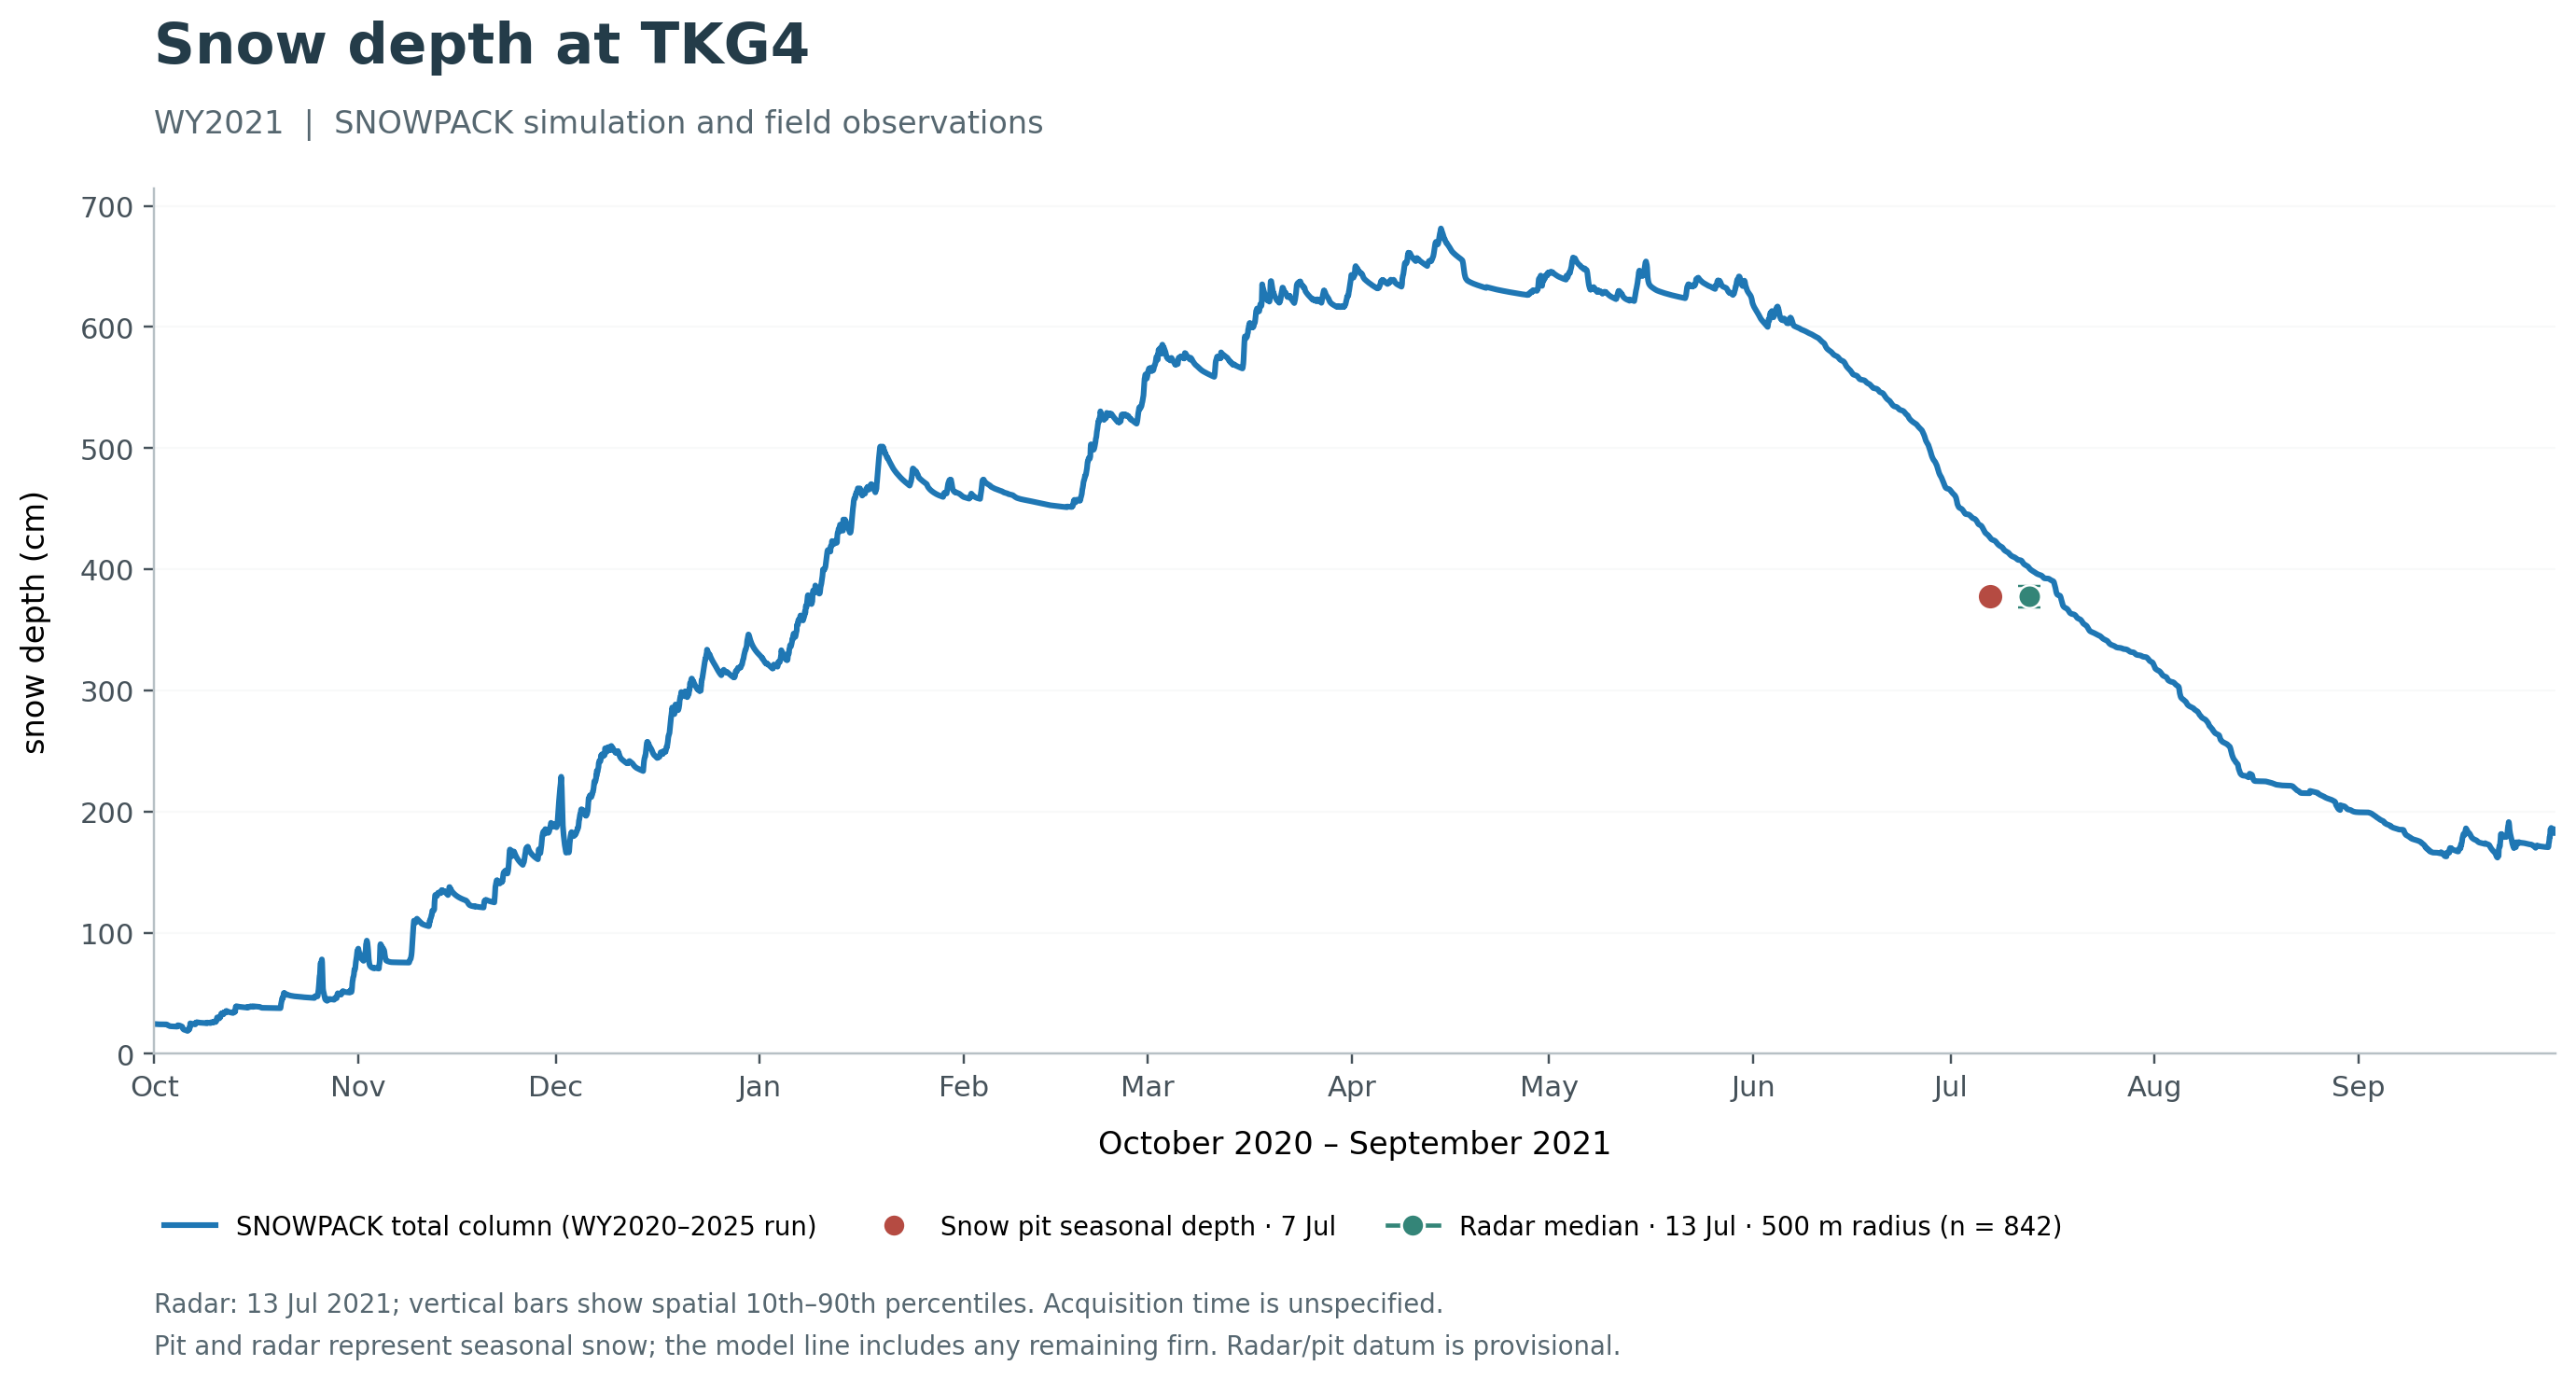

In [ ]:
# Snow depth: a single full water-year time series.
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

SAVE_SNOW_DEPTH_FIGURE = True
DEPTH_FIGURE_DIR = REPO_ROOT / 'sites/tkg4/figures'
# TKG4 radar date from the user-provided paper date table; time of day unknown.
radar_plot_date = RADAR_DATE
model_colors = ['tab:blue', 'tab:orange', 'tab:purple']
pit_color, radar_color = '#B54B42', '#348578'

with plt.rc_context({'font.size': 11, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.grid': False,
                     'savefig.facecolor': 'white'}):
    fig_depth, ax_depth = plt.subplots(figsize=(13, 6.8))
    fig_depth.subplots_adjust(left=0.08, right=0.98, top=0.86, bottom=0.24)
    depth_axes = [ax_depth]
    for i, (name, frame) in enumerate(models.items()):
        for ax in depth_axes:
            ax.plot(frame.index, frame.total_depth_m * 100,
                    color=model_colors[i % len(model_colors)], lw=2, zorder=2)
    for ax in depth_axes:
        ax.scatter(pit.dig_date, pit.seasonal_depth_m * 100, s=85, marker='o',
                   color=pit_color, edgecolor='white', linewidth=1, zorder=6)
        if not local.empty:
            radar_p10, radar_median, radar_p90 = (local.aa_avg_depth_m * 100).quantile([0.1, 0.5, 0.9])
            ax.errorbar(mdates.date2num(radar_plot_date), radar_median,
                        yerr=np.array([[radar_median-radar_p10], [radar_p90-radar_median]]),
                        fmt='o', markersize=8, color=radar_color, ecolor=radar_color,
                        markeredgecolor='white', markeredgewidth=0.8,
                        elinewidth=1.5, capsize=4, zorder=5)
        ax.grid(axis='y', color='#DDE2E5', linewidth=0.7)
        ax.tick_params(colors='#46525A', labelsize=10)
        ax.spines['left'].set_color('#B7C0C5')
        ax.spines['bottom'].set_color('#B7C0C5')
        ax.set_axisbelow(True)
    ax_depth.set_xlim(START, END - pd.Timedelta(seconds=1))
    ax_depth.set_ylim(bottom=0)
    ax_depth.set_ylabel('snow depth (cm)', labelpad=10)
    ax_depth.xaxis.set_major_locator(mdates.MonthLocator())
    ax_depth.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
    ax_depth.yaxis.set_major_locator(MultipleLocator(100))
    ax_depth.set_xlabel('October 2020 – September 2021', labelpad=10)
    fig_depth.text(0.08, 0.95, 'Snow depth at TKG4', fontsize=20, weight='bold', color='#243C49')
    fig_depth.text(0.08, 0.90, 'WY2021  |  SNOWPACK simulation and field observations',
                   fontsize=11, color='#566770')
    handles = [Line2D([], [], color=model_colors[i % len(model_colors)], lw=2,
                      label='SNOWPACK total column' + (f' ({name})' if len(models)>1 else ' (WY2020–2025 run)'))
               for i, name in enumerate(models)]
    handles.append(Line2D([], [], marker='o', color=pit_color, linestyle='none',
                          markeredgecolor='white', markersize=8, label='Snow pit seasonal depth · 7 Jul'))
    if not local.empty:
        handles.append(Line2D([], [], marker='o', color=radar_color, linestyle='-',
                              markeredgecolor='white', markersize=8,
                              label=f'Radar median · 13 Jul · {RADAR_RADIUS_M:g} m radius (n = {len(local):,})'))
    fig_depth.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.075, 0.09),
                     ncol=1 if len(models)>1 else 3, frameon=False, fontsize=9, handlelength=2)
    fig_depth.text(0.08, 0.055,
        'Radar: 13 Jul 2021; vertical bars show spatial 10th–90th percentiles. Acquisition time is unspecified.',
        fontsize=9, color='#566770')
    fig_depth.text(0.08, 0.025,
        'Pit and radar represent seasonal snow; the model line includes any remaining firn. Radar/pit datum is provisional.',
        fontsize=9, color='#566770')
    if SAVE_SNOW_DEPTH_FIGURE:
        DEPTH_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        for extension in ['png', 'pdf']:
            path = DEPTH_FIGURE_DIR / f'tkg4_snow_depth_WY2021.{extension}'
            fig_depth.savefig(path, dpi=220, bbox_inches='tight')
            print('Saved:', path)
    plt.show()


## Full simulation record and WY2021 snow depth

Two equal-width panels use a **1:2 height ratio**: the complete record of each run covering WY2021 above, and WY2021 with the pit/radar observations below. The transparent window in the upper panel marks the lower panel's timeframe. Both panels retain the original model values, with no depth offset or seasonal reset.

Use Seaborn's `darkgrid` theme and `tab10` palette. HRRR-AK retains the **`tab:blue`** line used in the earlier TKG4 notebooks and the single-panel figure above. Radar is dated 13 July; vertical bars retain the local spatial 10th–90th percentiles.

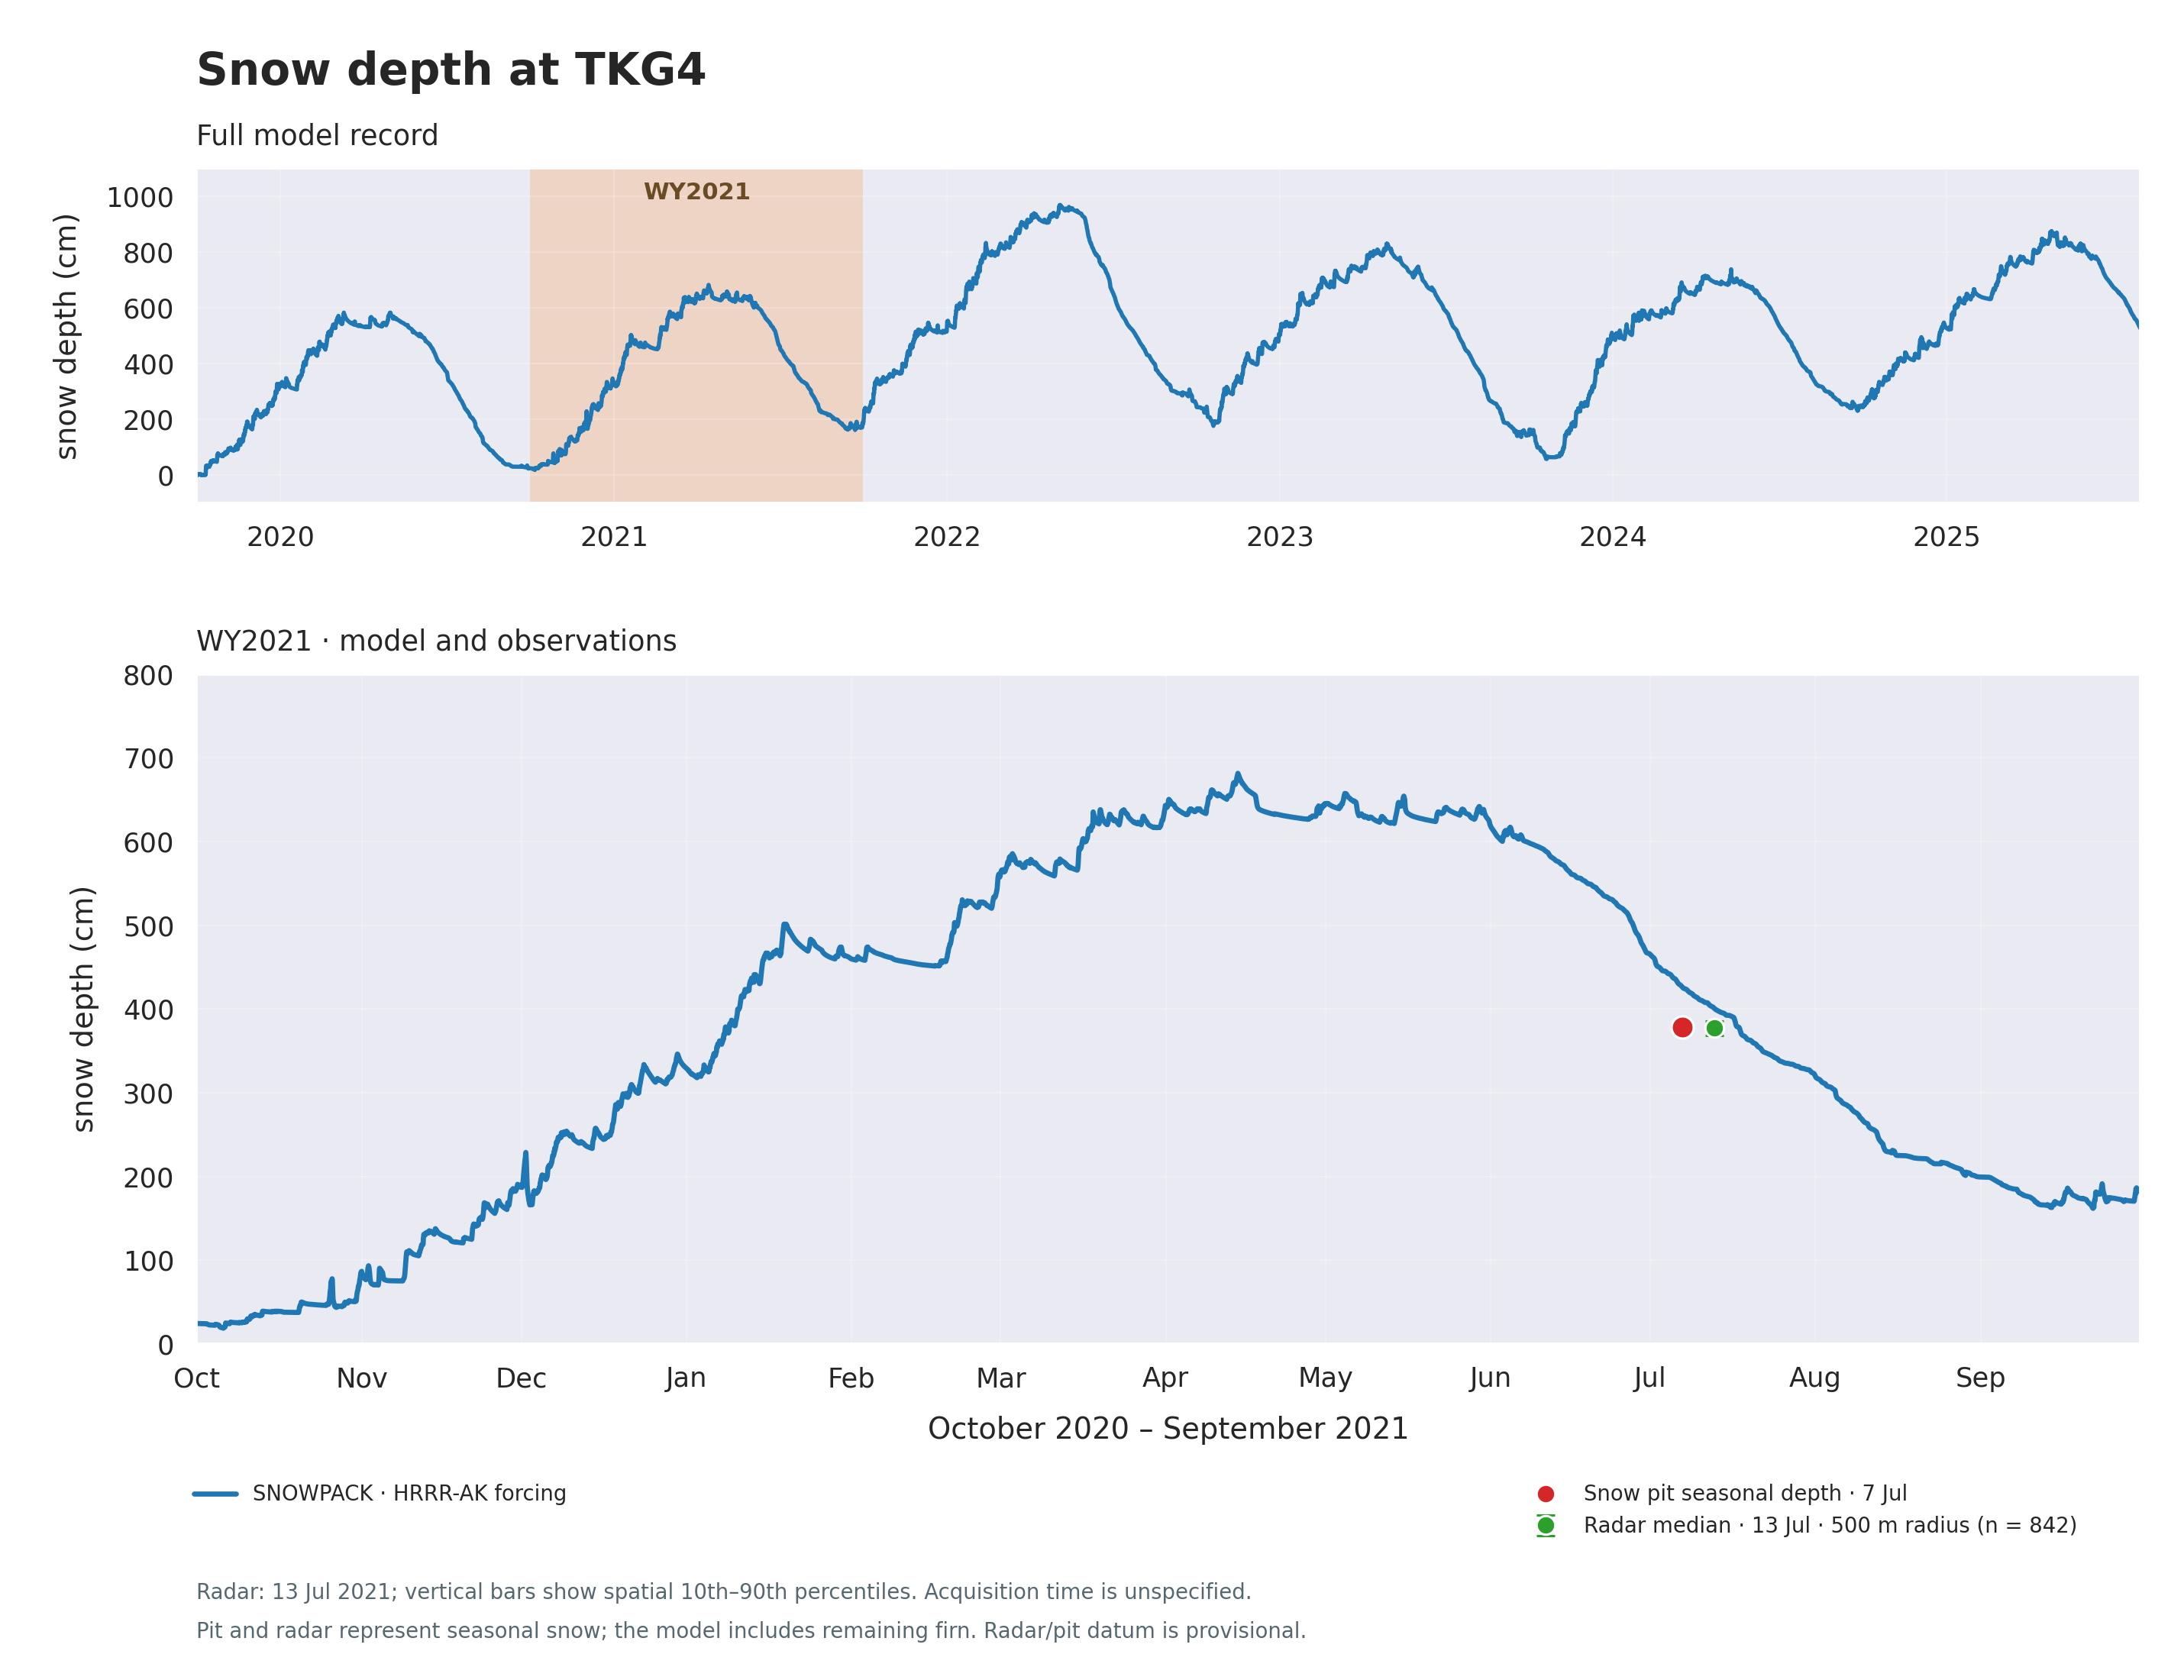

In [ ]:
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.ticker import MultipleLocator

# Find each autumn minimum around 1 October, rather than the boundary value.
adjusted_models, baseline_rows = {}, []
for name, full in full_models.items():
    adjusted = full.copy()
    adjusted['water_year'] = adjusted.index.year + (adjusted.index.month >= 10).astype(int)
    adjusted['autumn_minimum_m'] = np.nan
    adjusted['depth_above_minimum_m'] = np.nan
    for wy, group in adjusted.groupby('water_year'):
        window_start = pd.Timestamp(year=int(wy)-1, month=8, day=1)
        window_end = pd.Timestamp(year=int(wy)-1, month=11, day=1)
        candidates = full.loc[(full.index >= window_start) & (full.index < window_end), 'total_depth_m'].dropna()
        baseline_time = candidates.idxmin() if not candidates.empty else pd.NaT
        baseline = candidates.min()
        adjusted.loc[group.index, 'autumn_minimum_m'] = baseline
        adjusted.loc[group.index, 'depth_above_minimum_m'] = group.total_depth_m - baseline
        expected = int((window_end-window_start)/pd.Timedelta(hours=1))
        baseline_rows.append({'run': name, 'water_year': int(wy),
            'minimum_date_UTC': baseline_time, 'autumn_minimum_cm': baseline*100,
            'window_start_UTC': window_start, 'window_end_exclusive_UTC': window_end,
            'available_hours': len(candidates), 'expected_hours': expected,
            'complete_window': len(candidates)==expected})
    adjusted_models[name] = adjusted
baseline_audit = pd.DataFrame(baseline_rows)

# Fixed layout and limits shared by both exported figures; no tight cropping.
plot_palette = sns.color_palette('tab10')
model_run_colors = {name: model_colors[i % len(model_colors)] for i, name in enumerate(models)}
FULL_XLIM = (min(f.index.min() for f in full_models.values()), max(f.index.max() for f in full_models.values()))
WY_XLIM = (START, END-pd.Timedelta(seconds=1))
def common_depth_limits(frames, wy_only=False):
    values = [pit.seasonal_depth_m*100]
    if not local.empty:
        values.extend((local.aa_avg_depth_m*100).quantile([0.1, 0.9]).tolist())
    for frame in frames.values():
        view = frame.loc[(frame.index>=START) & (frame.index<END)] if wy_only else frame
        for column in ['total_depth_m', 'depth_above_minimum_m']:
            finite = view[column].dropna()*100
            if not finite.empty:
                values.extend([finite.min(), finite.max()])
    return (min(0, np.floor(min(values)/100)*100), np.ceil(max(values)*1.04/100)*100)
FULL_YLIM = common_depth_limits(adjusted_models)
WY_YLIM = common_depth_limits(adjusted_models, wy_only=True)

def plot_depth_overview(include_adjustment=False):
    with sns.axes_style('darkgrid'), sns.plotting_context('notebook', font_scale=1.05):
        fig, (ax_all, ax_wy) = plt.subplots(2, 1, figsize=(13, 10),
                                          gridspec_kw={'height_ratios': [1, 2]})
        fig.subplots_adjust(left=0.09, right=0.98, top=0.90, bottom=0.20, hspace=0.34)
        model_handles, adjusted_handles = [], []
        for name, full in full_models.items():
            label = 'SNOWPACK · HRRR-AK forcing' + (f' ({name})' if len(models)>1 else '')
            color = model_run_colors[name]
            ax_all.plot(full.index, full.total_depth_m*100, color=color, lw=1.8)
            wy = models[name]
            ax_wy.plot(wy.index, wy.total_depth_m*100, color=color, lw=2.2)
            model_handles.append(Line2D([], [], color=color, lw=2.2, label=label))
            if include_adjustment:
                adjusted = adjusted_models[name]
                orange = adjusted.depth_above_minimum_m.copy()*100
                orange.loc[adjusted.water_year.ne(adjusted.water_year.shift())] = np.nan
                ax_all.plot(orange.index, orange, color=plot_palette[1], lw=2, zorder=3)
                orange_wy = orange.loc[(orange.index>=START) & (orange.index<END)]
                ax_wy.plot(orange_wy.index, orange_wy, color=plot_palette[1], lw=2.2, zorder=3)
                adjusted_handles.append(Line2D([], [], color=plot_palette[1], lw=2.2,
                                               label='Model minus autumn minimum'))
        ax_all.axvspan(START, END, facecolor=plot_palette[1], alpha=0.20, edgecolor='none', zorder=0.5)
        ax_all.text(START+(END-START)/2, 0.96, 'WY2021', transform=ax_all.get_xaxis_transform(),
                    ha='center', va='top', fontsize=10, color='#6A4C24', weight='bold')
        ax_wy.scatter(pit.dig_date, pit.seasonal_depth_m*100, color=plot_palette[3],
                      marker='o', s=90, edgecolor='white', linewidth=1, zorder=6)
        pit_handle = Line2D([], [], marker='o', color=plot_palette[3], linestyle='none',
                            markeredgecolor='white', markersize=8, label='Snow pit seasonal depth · 7 Jul')
        radar_handle = Line2D([], [], color='none', label=' ')
        if not local.empty:
            low, median, high = (local.aa_avg_depth_m*100).quantile([0.1, 0.5, 0.9])
            radar_handle = ax_wy.errorbar(mdates.date2num(radar_plot_date), median,
                yerr=np.array([[median-low], [high-median]]),
                fmt='o', color=plot_palette[2], ecolor=plot_palette[2], markersize=8,
                markeredgecolor='white', markeredgewidth=1, capsize=4, elinewidth=1.5, zorder=5,
                label=f'Radar median · 13 Jul · {RADAR_RADIUS_M:g} m radius (n = {len(local):,})')
        ax_all.set(xlim=FULL_XLIM, ylim=FULL_YLIM)
        ax_wy.set(xlim=WY_XLIM, ylim=WY_YLIM)
        ax_all.xaxis.set_major_locator(mdates.YearLocator())
        ax_all.xaxis.set_major_formatter(mdates.DateFormatter('%Y'))
        ax_all.xaxis.set_minor_locator(mdates.MonthLocator(bymonth=[4, 7, 10]))
        ax_wy.xaxis.set_major_locator(mdates.MonthLocator())
        ax_wy.xaxis.set_major_formatter(mdates.DateFormatter('%b'))
        ax_all.set_title('Full model record', loc='left', fontsize=12, pad=10)
        ax_wy.set_title('WY2021 · model and observations', loc='left', fontsize=12, pad=10)
        ax_wy.set_xlabel('October 2020 – September 2021', labelpad=10)
        for ax in (ax_all, ax_wy):
            ax.set_ylabel('snow depth (cm)', labelpad=10)
            ax.yaxis.set_major_locator(MultipleLocator(200 if ax is ax_all else 100))
            ax.grid(True, which='major', linewidth=0.8)
        fig.suptitle('Snow depth at TKG4', x=0.09, ha='left', fontsize=19, weight='bold', y=0.97)
        # Reserve the same second legend slot for the orange line in both figures.
        blank = Line2D([], [], color='none', label=' ')
        handles = [model_handles[0], adjusted_handles[0] if adjusted_handles else blank,
                   pit_handle, radar_handle]
        if len(model_handles)>1:
            handles.extend(model_handles[1:])
        fig.legend(handles=handles, loc='lower left', bbox_to_anchor=(0.085, 0.08, 0.87, 0.07),
                   mode='expand', ncol=2, frameon=False, fontsize=9, borderaxespad=0)
        fig.text(0.09, 0.048,
            'Radar: 13 Jul 2021; vertical bars show spatial 10th–90th percentiles. Acquisition time is unspecified.',
            fontsize=9, color='#566770')
        note = ('Orange subtracts the autumn minimum; compaction/melt of older firn is not tracked.' if include_adjustment
                else 'Pit and radar represent seasonal snow; the model includes remaining firn. Radar/pit datum is provisional.')
        fig.text(0.09, 0.025, note, fontsize=9, color='#566770')
        return fig, (ax_all, ax_wy)

SAVE_OVERVIEW_FIGURE = True
fig_overview, overview_axes = plot_depth_overview()
if SAVE_OVERVIEW_FIGURE:
    DEPTH_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ['png', 'pdf']:
        fig_overview.savefig(DEPTH_FIGURE_DIR / f'tkg4_snow_depth_full_record_WY2021.{extension}',
                             dpi=220, bbox_inches=None)
plt.show()


## Autumn-minimum adjustment

The orange line subtracts the minimum modeled depth in **1 August–31 October around each water-year boundary** from the following water year's total column. This follows the autumn low rather than fixing the reference to 1 October. The baseline audit records the minimum date, actual window coverage, and whether the window is complete. At the simulation's initial boundary, only the available part of the window is used and flagged as partial.

This is a fixed-depth approximation to new accumulation, not layer-resolved seasonal snow: it cannot track compaction or melt of old firn. Differences below zero remain visible. Curves break at water-year boundaries. Both stacked figures use the same canvas, panel positions, axis limits/ticks, and two-column legend slots for direct PowerPoint alignment.

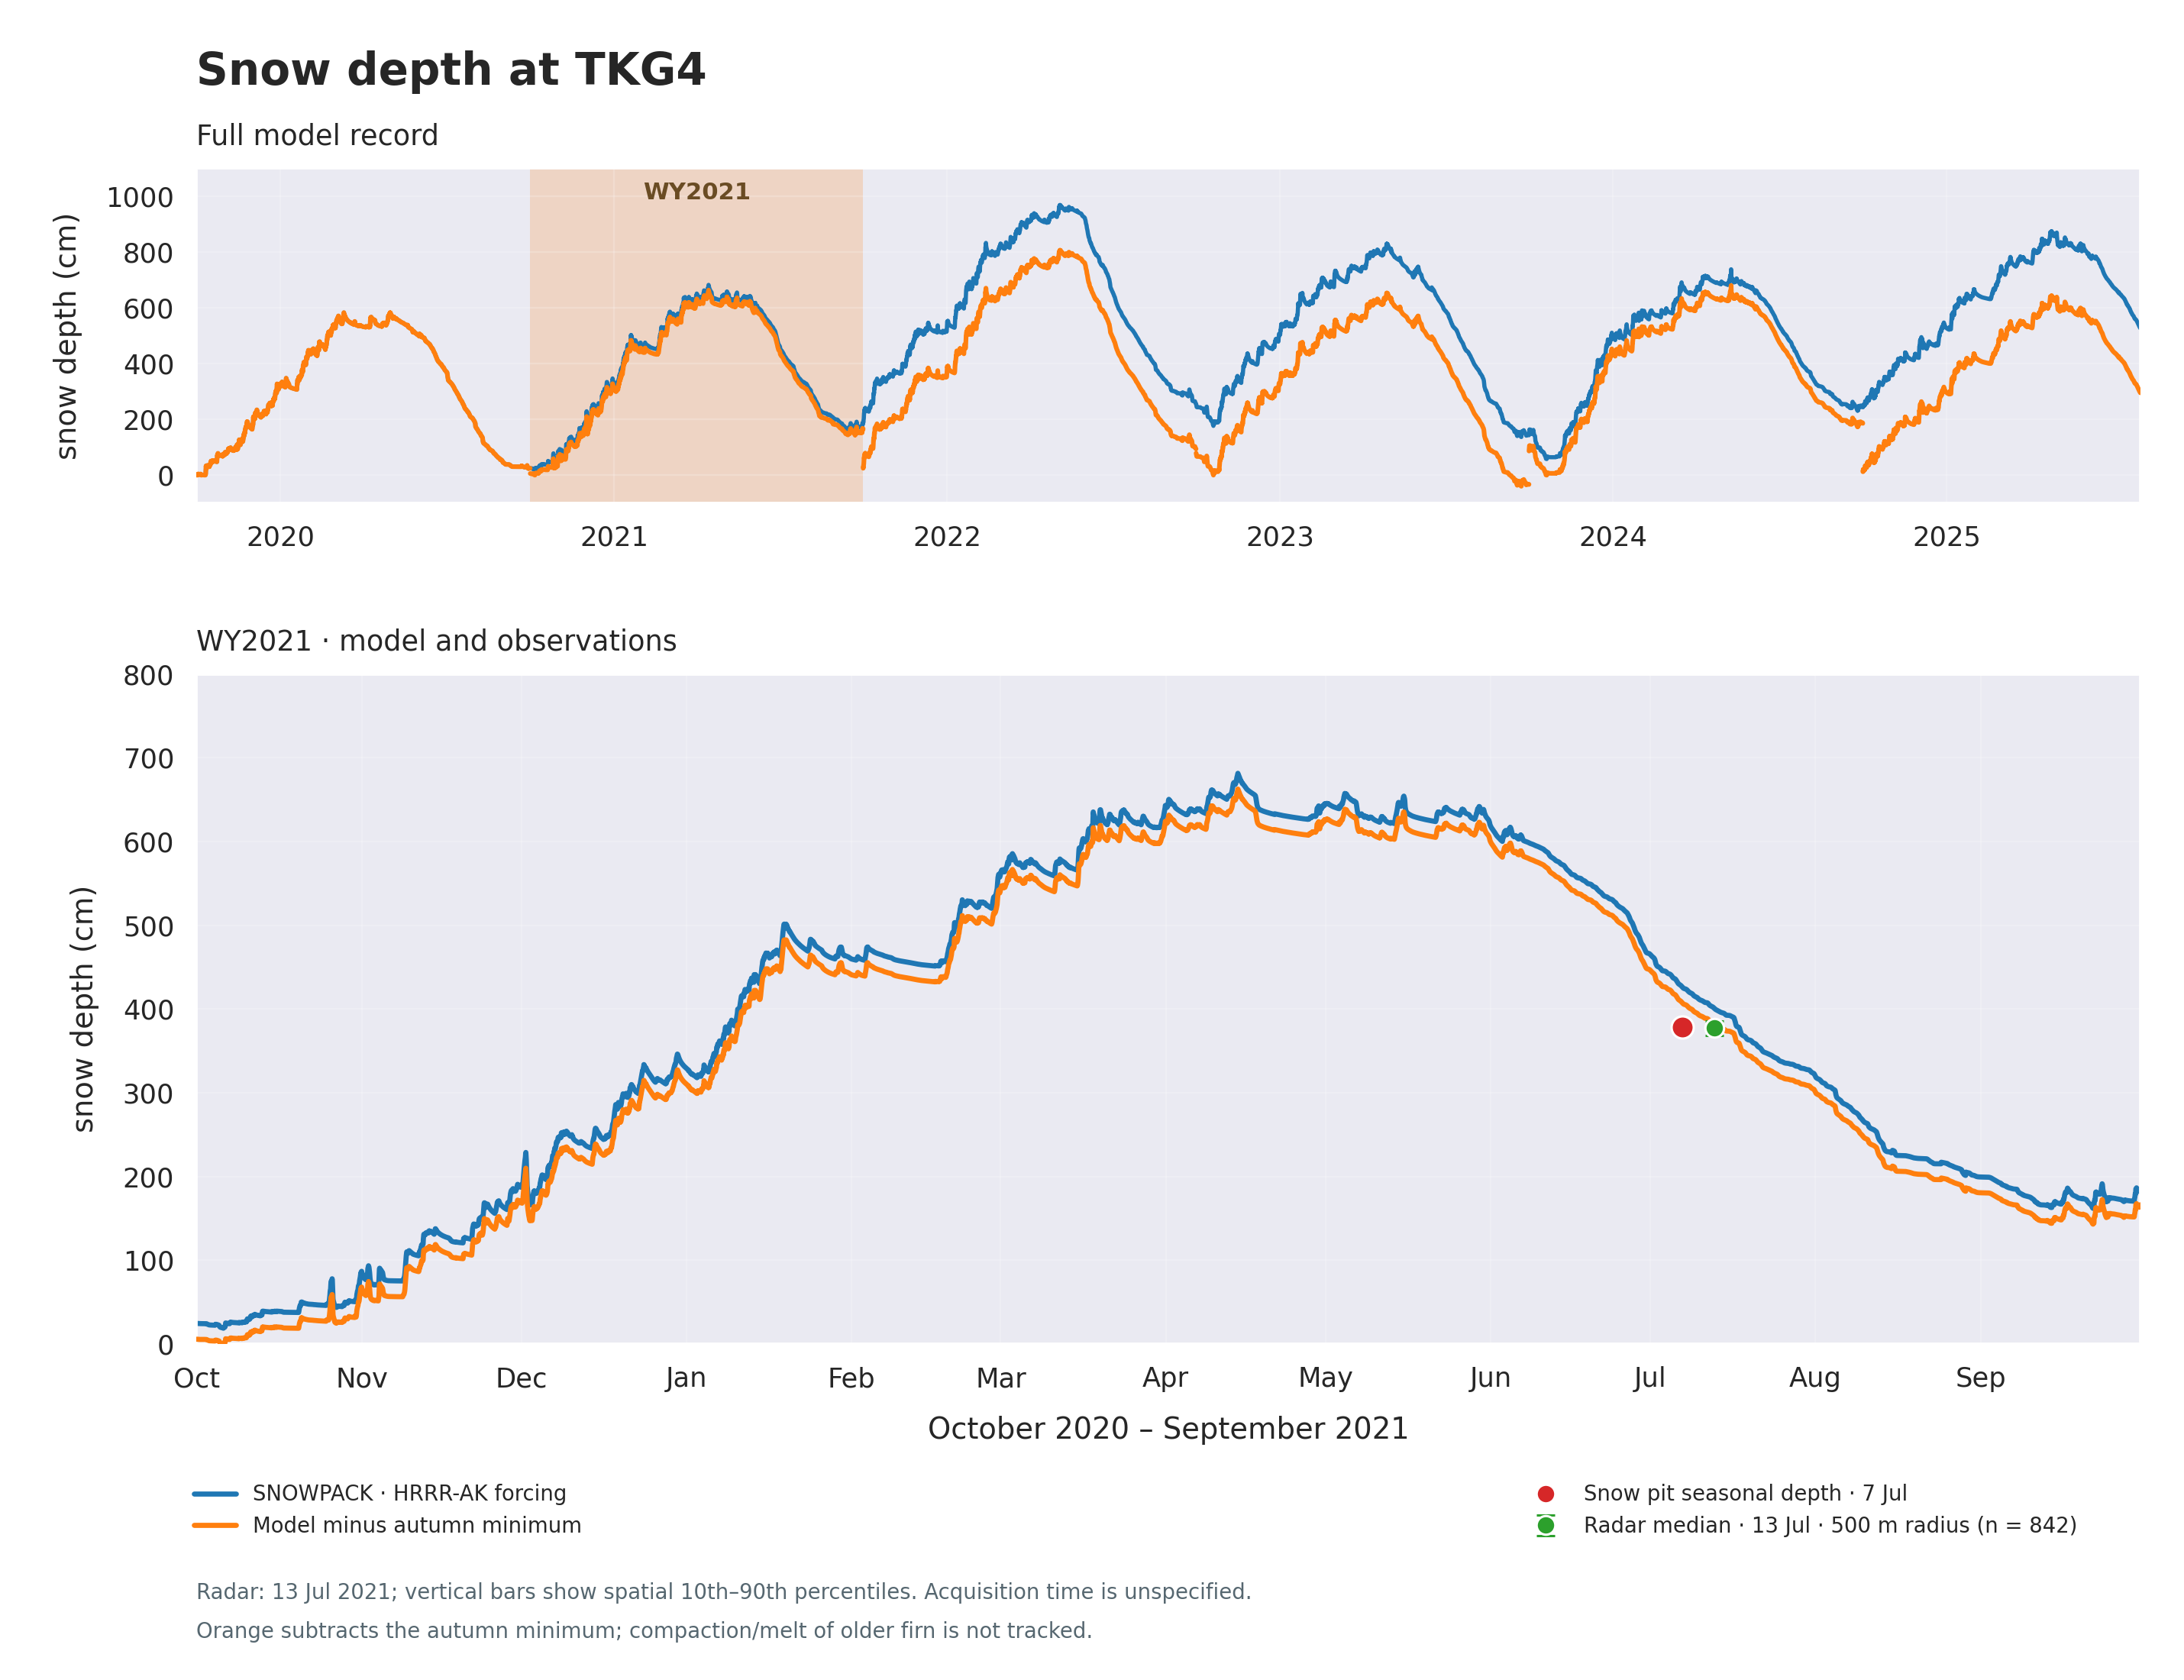

In [ ]:
SAVE_ADJUSTED_FIGURE = True
fig_adjusted, adjusted_axes = plot_depth_overview(include_adjustment=True)
if SAVE_ADJUSTED_FIGURE:
    DEPTH_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
    for extension in ['png', 'pdf']:
        fig_adjusted.savefig(DEPTH_FIGURE_DIR / f'tkg4_snow_depth_carryover_adjustment_WY2021.{extension}',
                             dpi=220, bbox_inches=None)
plt.show()


## Snow-depth comparison (cm)

Pit depth uses the **7 July dig date**. Radar uses **13 July 2021**, from the user-provided paper date table, with its local spatial median and 10th–90th percentiles. Model values summarize all available hourly values in the corresponding UTC day; mean and min–max express temporal variation, not uncertainty. Field timezones are unrecorded. Model-minus-observation differences are descriptive and compare different column definitions; the adjusted model remains a fixed-baseline approximation.

Print the comparison and the annual baselines below. This keeps the original pit date distinct from density sampling on 8 July.

In [ ]:
comparison_rows = []
observation_windows = [
    ('Snow pit', pit.dig_date, pit.dig_date + pd.Timedelta(days=1),
     pit.seasonal_depth_m * 100, np.nan, np.nan, 1),
]
if not local.empty:
    low, median, high = (local.aa_avg_depth_m * 100).quantile([0.1, 0.5, 0.9])
    observation_windows.append(('Radar', RADAR_START, RADAR_END, median, low, high, len(local)))
for name, adjusted in adjusted_models.items():
    for source, start, end, observed, low, high, count in observation_windows:
        window = adjusted.loc[(adjusted.index >= start) & (adjusted.index < end)]
        total = window.total_depth_m * 100
        corrected = window.depth_above_minimum_m * 100
        comparison_rows.append({
            'run': name, 'observation': source,
            'start_date': start.date(), 'end_date_inclusive': (end-pd.Timedelta(days=1)).date(),
            'paper_GT_date': PAPER_GT_DATE.date() if source == 'Snow pit' else pd.NaT,
            'date_source': 'archived pit dig date; paper GT differs' if source == 'Snow pit' else 'paper GPR date supplied by user',
            'observation_count': count, 'observed_depth_cm': observed,
            'radar_spatial_p10_cm': low, 'radar_spatial_p90_cm': high,
            'expected_model_hours': int((end-start)/pd.Timedelta(hours=1)),
            'total_model_hours': total.count(), 'adjusted_model_hours': corrected.count(),
            'model_total_mean_cm': total.mean(), 'model_total_min_cm': total.min(), 'model_total_max_cm': total.max(),
            'autumn_minimum_cm': window.autumn_minimum_m.mean()*100,
            'model_adjusted_mean_cm': corrected.mean(),
            'model_adjusted_min_cm': corrected.min(), 'model_adjusted_max_cm': corrected.max(),
            'total_mean_minus_observed_cm': total.mean()-observed,
            'adjusted_mean_minus_observed_cm': corrected.mean()-observed,
        })
snow_depth_comparison = pd.DataFrame(comparison_rows)
print('Snow-depth comparison — all depths in cm:')
print(snow_depth_comparison.round(2).to_string(index=False))
display(snow_depth_comparison.round(2).T)
print('Autumn-minimum baselines (not layer-resolved firn thickness):')
print(baseline_audit.round(2).to_string(index=False))
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    snow_depth_comparison.to_csv(OUTPUT_DIR / 'snow_depth_comparison_cm.csv', index=False)
    baseline_audit.to_csv(OUTPUT_DIR / 'annual_autumn_minimum_cm.csv', index=False)


Snow-depth comparison — all depths in cm:
                                             run observation start_date end_date_inclusive paper_GT_date                             date_source  observation_count  observed_depth_cm  radar_spatial_p10_cm  radar_spatial_p90_cm  expected_model_hours  total_model_hours  adjusted_model_hours  model_total_mean_cm  model_total_min_cm  model_total_max_cm  autumn_minimum_cm  model_adjusted_mean_cm  model_adjusted_min_cm  model_adjusted_max_cm  total_mean_minus_observed_cm  adjusted_mean_minus_observed_cm
hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero    Snow pit 2021-07-07         2021-07-07    2021-07-13 archived pit dig date; paper GT differs                  1             378.00                   NaN                   NaN                    24                 24                    24               424.10              422.19              426.11              18.85                  405.25                 403.34                 407.26                

,0,1
run,hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero,hrrrak_tkg4_WY2020-WY2025_heatflux_soiltemp_zero
observation,Snow pit,Radar
start_date,2021-07-07,2021-07-13
end_date_inclusive,2021-07-07,2021-07-13
paper_GT_date,2021-07-13,NaT
date_source,archived pit dig date; paper GT differs,paper GPR date supplied by user
observation_count,1,842
observed_depth_cm,378.0,377.89
radar_spatial_p10_cm,NaN,368.52
radar_spatial_p90_cm,NaN,386.04


## Model values across the observation dates

Report each day's available hourly values (mean, minimum, maximum, and count), preserving timing ambiguity rather than choosing midnight as a measurement time. July 7–8 cover digging/sampling; 13 July is the paper-reported TKG4 radar/GT date. Daily values are not interpolated. These are total-column values, so no seasonal-observation error metric is calculated.

A future seasonal comparison should identify the 2020/21 horizon in the model layer profiles. Subtracting an autumn depth baseline alone cannot track firn compaction or identify the seasonal snow layer.

In [ ]:
daily_rows = []
for name, frame in models.items():
    for day in pd.date_range(pit.dig_date, RADAR_END, inclusive='left', freq='D'):
        day_frame = frame.loc[(frame.index >= day) & (frame.index < day + pd.Timedelta(days=1))]
        row = {'run': name, 'date_UTC': day, 'period': 'radar / paper GT' if day == RADAR_DATE else ('pit dig/sample' if day in [pit.dig_date, pit.sample_date] else 'between observations')}
        for variable in ['total_depth_m', 'total_swe_m']:
            values = day_frame[variable]
            row.update({f'{variable}_{stat}': getattr(values, stat)() for stat in ['count', 'mean', 'min', 'max']})
        daily_rows.append(row)
model_daily = pd.DataFrame(daily_rows)
display(model_daily)
if SAVE_OUTPUTS:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    pit.to_frame('value').to_csv(OUTPUT_DIR / 'pit_metadata.csv')
    pit_profile.to_csv(OUTPUT_DIR / 'pit_density_profile.csv', index=False)
    model_audit.to_csv(OUTPUT_DIR / 'model_source_audit.csv', index=False)
    locations.to_csv(OUTPUT_DIR / 'locations.csv', index=False)
    local_all.to_csv(OUTPUT_DIR / 'radar_local_all_with_flags.csv', index=False)
    radar_summary.to_csv(OUTPUT_DIR / 'radar_radius_summary.csv')
    model_daily.to_csv(OUTPUT_DIR / 'model_daily_observation_dates.csv', index=False)
    print('Saved tables to', OUTPUT_DIR)

## Next steps

- Inspect the modeled layer profiles (`.pro`) to separate 2020/21 seasonal snow from older firn before calculating model errors against the pit or radar.
- Add the paper citation for the supplied 13 July TKG4 GPR/GT date and resolve its difference from the archived pit dates; confirm the coordinate datum and prescribed radar density/permittivity. Pit and radar SWE may share density information.
- Review the radius sensitivity, profile coverage, duplicates, and pit/model elevation difference before settling on a representative radar footprint.
- Preserve the distinction between 7 July digging, 8 July sampling, and 13 July radar / paper GT date when interpreting melt between observations.

References: the existing `3_read_snowpack_output*.ipynb` files in this directory and `radar/01_explore_radar_2021.ipynb` / `radar/03_radar_hrrrak_snowpits.ipynb`.